# DS1 data preprocessing

Prepares DS1 (UCI Chronic Kidney Disease, CKD vs not CKD) for clustering and the models. Input is the train/test split from `4_Feature_Selection/data_split.ipynb` (`final_data/`), found through `configs/config.json`. Output is `preprocessed_data/DS1_train.csv` and `preprocessed_data/DS1_test.csv`: no missing values, numbers scaled, text encoded as 0/1.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, StandardScaler, FunctionTransformer

root = Path.cwd()
while not (root / "configs" / "config.json").is_file():
    root = root.parent

config = json.loads((root / "configs" / "config.json").read_text())
ds = config["datasets"]["list"]["DS1"]
base = (root / "configs" / config["paths"]["datasets_dir"] / ds["folder"]).resolve()
target = ds["target"]["column"]

names = {
    "age": "Age", "bp": "Blood pressure", "sg": "Specific gravity", "al": "Albumin", "su": "Sugar",
    "rbc": "Red blood cells", "pc": "Pus cells", "pcc": "Pus cell clumps", "ba": "Bacteria",
    "bgr": "Blood glucose", "bu": "Blood urea", "sc": "Serum creatinine", "sod": "Sodium", "pot": "Potassium",
    "hemo": "Hemoglobin", "pcv": "Packed cell volume", "wbcc": "White blood cell count", "rbcc": "Red blood cell count",
    "htn": "Hypertension", "dm": "Diabetes mellitus", "cad": "Coronary artery disease", "appet": "Appetite",
    "pe": "Pedal edema", "ane": "Anemia",
}

## 1. Load the train/test split

In [2]:
train_df = pd.read_csv(base / ds["files"]["final"]["train"])
test_df = pd.read_csv(base / ds["files"]["final"]["test"])

X_train, y_train = train_df.drop(columns=[target]), train_df[target]
X_test, y_test = test_df.drop(columns=[target]), test_df[target]

print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (320, 24) Test: (80, 24)


**Observation:**
- The split (stratified 80/20) is made in `data_split.ipynb`, so all notebooks use the same patients
- Every decision below uses the training set only; the test set is only transformed (Géron, 2022)

## 2. Explore the training set

**Feature groups**

| Group | Features | Role |
|---|---|---|
| Kidney function (4) | serum creatinine, blood urea, albumin, specific gravity | Main CKD markers (KDIGO, 2024) |
| Blood tests (7) | hemoglobin, packed cell volume, red and white cell counts, sodium, potassium, glucose | CKD complications such as anemia |
| Urine tests (5) | sugar, red cells, pus cells, pus cell clumps, bacteria | Kidney damage |
| Medical history (6) | hypertension, diabetes, coronary artery disease, appetite, pedal edema, anemia | Known risk factors |
| Demographics (2) | age, blood pressure | Basic patient profile |

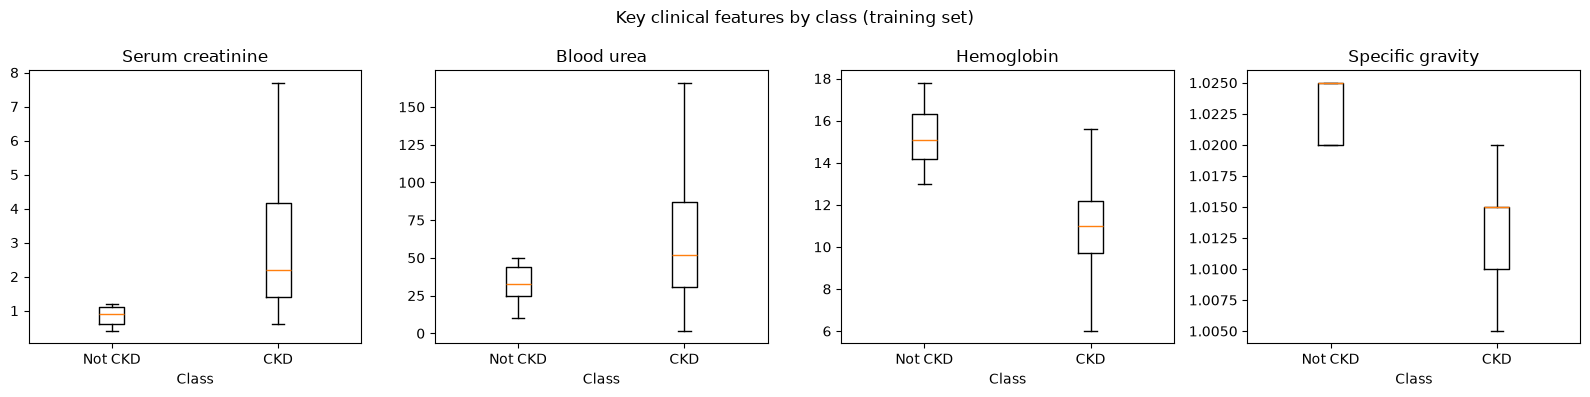

In [3]:
num_cols = [c for c in X_train.columns if pd.api.types.is_numeric_dtype(X_train[c])]
text_cols = [c for c in X_train.columns if c not in num_cols]

order = ["notckd", "ckd"]
short = ["Not CKD", "CKD"]
key = ["sc", "bu", "hemo", "sg"]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, key):
    ax.boxplot([X_train.loc[y_train == c, col].dropna() for c in order], tick_labels=short, showfliers=False)
    ax.set_title(names[col])
    ax.set_xlabel("Class")
fig.suptitle("Key clinical features by class (training set)")
fig.tight_layout()
plt.show()

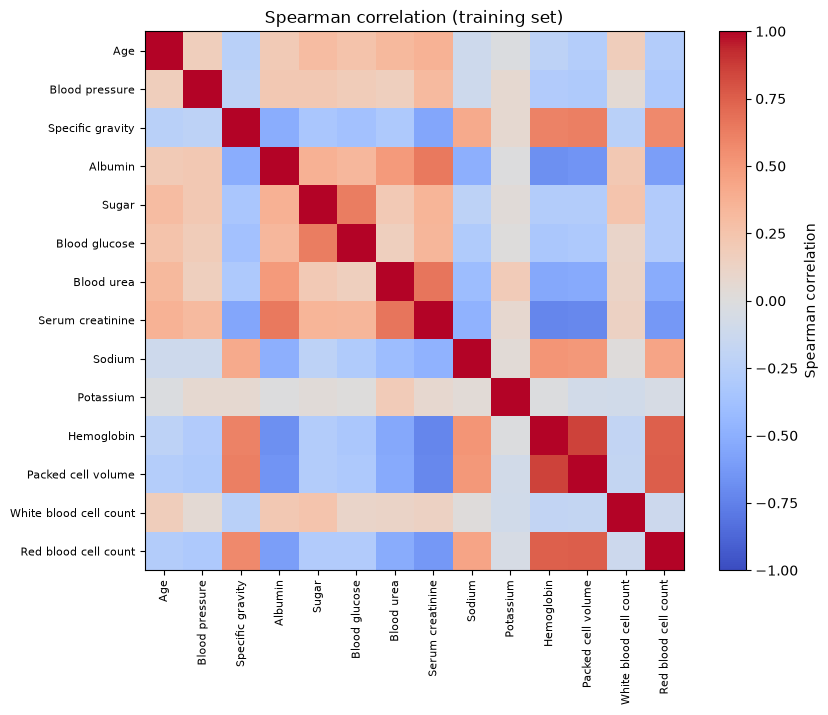

Largest correlation: Hemoglobin and Packed cell volume, 0.86


In [4]:
corr = X_train[num_cols].corr(method="spearman")
labels = [names[c] for c in num_cols]
plt.figure(figsize=(9, 7))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Spearman correlation")
plt.xticks(range(len(labels)), labels, rotation=90, fontsize=8)
plt.yticks(range(len(labels)), labels, fontsize=8)
plt.title("Spearman correlation (training set)")
plt.show()

off = corr.where(~np.eye(len(corr), dtype=bool)).abs().stack()
a, b = off.idxmax()
print(f"Largest correlation: {names[a]} and {names[b]}, {off.max():.2f}")

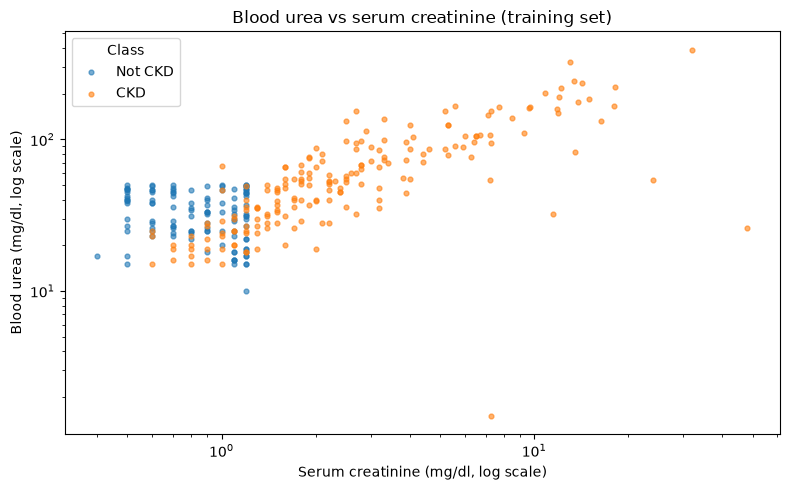

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
for c, s in zip(order, short):
    m = y_train == c
    ax.scatter(X_train.loc[m, "sc"], X_train.loc[m, "bu"], s=12, alpha=0.6, label=s)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Serum creatinine (mg/dl, log scale)")
ax.set_ylabel("Blood urea (mg/dl, log scale)")
ax.legend(title="Class")
ax.set_title("Blood urea vs serum creatinine (training set)")
fig.tight_layout()
plt.show()

**Observation:**
- CKD patients have higher creatinine and urea and lower hemoglobin and specific gravity
- Hemoglobin and packed cell volume are strongly correlated (0.86), as expected
- Urea rises with creatinine, as in real patients

## 3. Missing values, outliers and impossible values

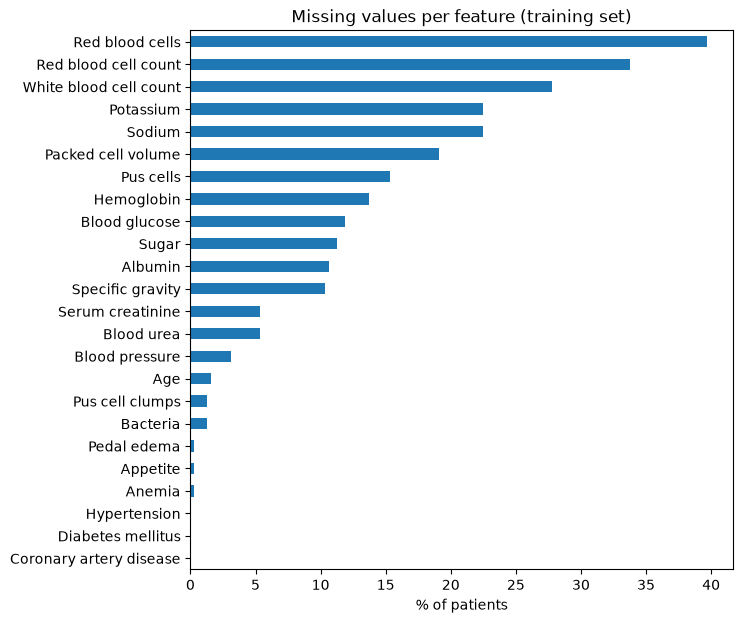

Training rows with at least one missing value: 62%


In [6]:
missing = X_train.isnull().mean().mul(100).sort_values().rename(index=names)
missing.plot(kind="barh", figsize=(7, 7), title="Missing values per feature (training set)")
plt.xlabel("% of patients")
plt.show()
print("Training rows with at least one missing value:", f"{X_train.isnull().any(axis=1).mean():.0%}")

In [7]:
q1 = X_train[num_cols].quantile(0.25)
q3 = X_train[num_cols].quantile(0.75)
iqr = q3 - q1
outliers = (X_train[num_cols] < q1 - 1.5 * iqr) | (X_train[num_cols] > q3 + 1.5 * iqr)
display(outliers.sum().sort_values(ascending=False).head(6).rename(index=names).to_frame("Outliers (IQR)"))

,Outliers (IQR)
Sugar,52
Serum creatinine,39
Blood glucose,35
Blood urea,30
Blood pressure,29
Sodium,12


In [8]:
for name, part in (("Train", X_train), ("Test", X_test)):
    low_sod, high_pot = part["sod"] < 100, part["pot"] > 10
    print(f"{name}: sodium {part.loc[low_sod, 'sod'].tolist()}, potassium {part.loc[high_pot, 'pot'].tolist()}")
    part.loc[low_sod, "sod"] = np.nan
    part.loc[high_pot, "pot"] = np.nan

Train: sodium [], potassium [47.0, 39.0]
Test: sodium [4.5], potassium []


**Observation:**
- Up to 40% missing per feature (red blood cells); dropping rows would lose 62% of training patients, so values are imputed in section 4
- IQR outliers in sugar, creatinine, glucose and urea are kept, because very high values are expected in kidney failure (KDIGO, 2024)
- 3 impossible values (potassium 47 and 39 in train, sodium 4.5 in test), likely typing errors, set to missing

## 4. Impute, encode and scale

In [9]:
binary_cats = {
    "rbc": ["normal", "abnormal"],
    "pc": ["normal", "abnormal"],
    "pcc": ["notpresent", "present"],
    "ba": ["notpresent", "present"],
    "htn": ["no", "yes"],
    "dm": ["no", "yes"],
    "cad": ["no", "yes"],
    "appet": ["good", "poor"],
    "pe": ["no", "yes"],
    "ane": ["no", "yes"],
}
unknown = set(text_cols) - set(binary_cats)
assert not unknown, f"New text columns need an encoding: {unknown}"

graded = ["sg", "al", "su"]
skewed = [c for c in num_cols if c not in graded and X_train[c].skew() > 1]
other_num = [c for c in num_cols if c not in skewed]
print("Log-transformed:", [names.get(c, c) for c in skewed])

preprocess = ColumnTransformer([
    ("log", make_pipeline(SimpleImputer(strategy="median"), FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler()), skewed),
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), other_num),
    ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"), OrdinalEncoder(categories=[binary_cats[c] for c in text_cols])), text_cols),
], verbose_feature_names_out=False).set_output(transform="pandas")

X_train_prep = preprocess.fit_transform(X_train)
X_test_prep = preprocess.transform(X_test)

print(X_train_prep.shape, X_test_prep.shape, "missing after:", X_train_prep.isnull().sum().sum() + X_test_prep.isnull().sum().sum())
display(X_train_prep.head())

Log-transformed: ['Blood glucose', 'Blood urea', 'Serum creatinine', 'White blood cell count']
(320, 24) (80, 24) missing after: 0


,bgr,bu,sc,wbcc,age,bp,sg,al,su,sod,...,rbc,pc,pcc,ba,htn,dm,cad,appet,pe,ane
0,-0.366492,-0.950125,-0.505884,-0.687628,0.469875,-1.313179,0.412298,-0.684861,-0.394777,0.185176,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,-0.223696,2.031924,2.092884,1.240055,1.486223,-0.514287,-0.503920,1.622039,3.293647,-1.075595,...,0.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,0.0
2,0.209884,1.614811,0.878642,0.122234,1.127512,1.083498,-0.503920,-0.684861,-0.394777,-0.287613,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0,0.0
3,-1.215166,0.215804,-1.042892,-0.687628,-1.383468,-1.313179,1.328515,-0.684861,-0.394777,1.130754,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,-0.680465,0.089465,-0.431639,-2.127836,-1.682394,0.284605,0.412298,-0.684861,-0.394777,0.657965,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


**Observation:**
- Missing values filled with the training median (numeric) or most frequent value (text), learned on train only (Géron, 2022)
- Glucose, urea, creatinine and white cell count are right-skewed (skew above 1), so they are log-transformed; then all numeric features are scaled (mean 0, std 1) for kNN and the MLP
- Specific gravity, albumin and sugar are graded scales, kept without a log transform
- Binary text features encoded 0/1 (abnormal, present, poor or yes = 1)
- No missing values remain

## 5. Save the preprocessed data

In [10]:
out = base / "preprocessed_data"
out.mkdir(exist_ok=True)

X_train_prep.assign(**{target: y_train.values}).to_csv(out / "DS1_train.csv", index=False)
X_test_prep.assign(**{target: y_test.values}).to_csv(out / "DS1_test.csv", index=False)
print(len(X_train_prep), "train rows,", len(X_test_prep), "test rows,", X_train_prep.shape[1], "features")

320 train rows, 80 test rows, 24 features


**Observation:**
- Same short column names as the config; Target kept as text (ckd, notckd)
- Clustering, kNN, Naive Bayes and the MLP use these files, as they need scaled data with no missing values

**GenAI:** code generated with Claude (Anthropic) under the course GenAI policy (Framework statement 6), then evaluated by me.